# Project on car price

In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [4]:
data = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dataset\car_price_regression_data (1).csv")

In [5]:
data

,Brand,Model,Year,Age_Years,Fuel_Type,Transmission,Engine_CC,Kilometers_Driven,Owner_Type,Mileage_kmpl,Seats,Safety_Rating,Price_Lakh
0,Hyundai,Creta,2021,3,Petrol,Automatic,1462,64757,First,21.8,5,2.5,9
1,Honda,City,2015,9,Petrol,Manual,998,182014,First,21.2,7,3.4,2
2,Nissan,Magnite,2017,7,Electric,Manual,0,115619,First,250.5,6,4.8,1
3,Mahindra,Scorpio-N,2016,8,Diesel,Manual,998,117605,First,15.3,5,2.3,4
4,Tata,Altroz,2023,1,Petrol,Manual,998,58118,First,14.4,5,4.6,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Toyota,Innova Crysta,2019,5,Electric,Manual,0,196361,First,324.9,6,3.8,9
96,Nissan,Magnite,2020,4,Petrol,Manual,1497,50908,First,18.8,5,2.9,4
97,Renault,Triber,2021,3,Petrol,Automatic,1956,34332,First,18.2,6,4.8,5
98,Kia,Sonet,2017,7,Petrol,Manual,1497,154893,First,16.1,5,4.8,2


In [6]:
data.info

<bound method DataFrame.info of          Brand          Model  Year  Age_Years Fuel_Type Transmission  \
0      Hyundai          Creta  2021          3    Petrol    Automatic   
1        Honda           City  2015          9    Petrol       Manual   
2       Nissan        Magnite  2017          7  Electric       Manual   
3     Mahindra      Scorpio-N  2016          8    Diesel       Manual   
4         Tata         Altroz  2023          1    Petrol       Manual   
..         ...            ...   ...        ...       ...          ...   
95      Toyota  Innova Crysta  2019          5  Electric       Manual   
96      Nissan        Magnite  2020          4    Petrol       Manual   
97     Renault         Triber  2021          3    Petrol    Automatic   
98         Kia          Sonet  2017          7    Petrol       Manual   
99  Volkswagen         Taigun  2024          0    Diesel       Manual   

    Engine_CC  Kilometers_Driven Owner_Type  Mileage_kmpl  Seats  \
0        1462          

In [8]:
data.describe()

,Year,Age_Years,Engine_CC,Kilometers_Driven,Mileage_kmpl,Seats,Safety_Rating,Price_Lakh
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,2019.910000,4.090000,1431.500000,114763.400000,50.350000,5.360000,3.608000,6.630000
std,3.025464,3.025464,686.507506,49846.676738,98.585301,0.659354,0.908399,5.500514
min,2015.000000,0.000000,0.000000,6015.000000,14.000000,5.000000,2.000000,1.000000
25%,2017.000000,1.750000,1147.250000,77464.000000,16.100000,5.000000,2.700000,3.000000
50%,2020.000000,4.000000,1497.000000,117945.500000,18.800000,5.000000,3.700000,5.500000
75%,2022.250000,7.000000,1612.500000,144517.000000,21.200000,6.000000,4.425000,9.000000
max,2024.000000,9.000000,2982.000000,200000.000000,448.200000,7.000000,5.000000,33.000000


In [9]:
data.columns

Index(['Brand', 'Model', 'Year', 'Age_Years', 'Fuel_Type', 'Transmission',
       'Engine_CC', 'Kilometers_Driven', 'Owner_Type', 'Mileage_kmpl', 'Seats',
       'Safety_Rating', 'Price_Lakh'],
      dtype='str')

In [10]:
data.isnull().sum()

Brand                0
Model                0
Year                 0
Age_Years            0
Fuel_Type            0
Transmission         0
Engine_CC            0
Kilometers_Driven    0
Owner_Type           0
Mileage_kmpl         0
Seats                0
Safety_Rating        0
Price_Lakh           0
dtype: int64

In [16]:
data.duplicated().sum()
# data.duplicated().sum()

np.int64(0)

In [23]:
for i in data.columns:
    print(f"{i}:",data[i].unique(), "\n")

Brand: <StringArray>
[      'Hyundai',         'Honda',        'Nissan',      'Mahindra',
          'Tata',    'Volkswagen',           'Kia',        'Toyota',
 'Maruti Suzuki',       'Renault',         'Skoda']
Length: 11, dtype: str 

Model: <StringArray>
[        'Creta',          'City',       'Magnite',     'Scorpio-N',
        'Altroz',         'Venue',         'Amaze',        'Taigun',
        'Carens', 'Urban Cruiser',      'Fortuner',         'Dzire',
        'Brezza', 'Innova Crysta',        'Baleno',       'Harrier',
         'Kiger',           'i20',        'Kushaq',         'Swift',
        'Virtus',        'Seltos',        'Slavia',        'Triber',
         'Nexon',          'Thar',       'Wagon R',         'Verna',
         'Sonet',        'XUV700']
Length: 30, dtype: str 

Year: [2021 2015 2017 2016 2023 2024 2020 2022 2018 2019] 

Age_Years: [3 9 7 8 1 0 4 2 6 5] 

Fuel_Type: <StringArray>
['Petrol', 'Electric', 'Diesel', 'CNG']
Length: 4, dtype: str 

Transmission: <S

In [27]:
data = data.drop(columns = ["Year",
"Engine_CC",
"Owner_Type",
"Mileage_kmpl"])

In [28]:
data

,Brand,Model,Age_Years,Fuel_Type,Transmission,Kilometers_Driven,Seats,Safety_Rating,Price_Lakh
0,Hyundai,Creta,3,Petrol,Automatic,64757,5,2.5,9
1,Honda,City,9,Petrol,Manual,182014,7,3.4,2
2,Nissan,Magnite,7,Electric,Manual,115619,6,4.8,1
3,Mahindra,Scorpio-N,8,Diesel,Manual,117605,5,2.3,4
4,Tata,Altroz,1,Petrol,Manual,58118,5,4.6,7
...,...,...,...,...,...,...,...,...,...
95,Toyota,Innova Crysta,5,Electric,Manual,196361,6,3.8,9
96,Nissan,Magnite,4,Petrol,Manual,50908,5,2.9,4
97,Renault,Triber,3,Petrol,Automatic,34332,6,4.8,5
98,Kia,Sonet,7,Petrol,Manual,154893,5,4.8,2


<Axes: xlabel='Brand'>

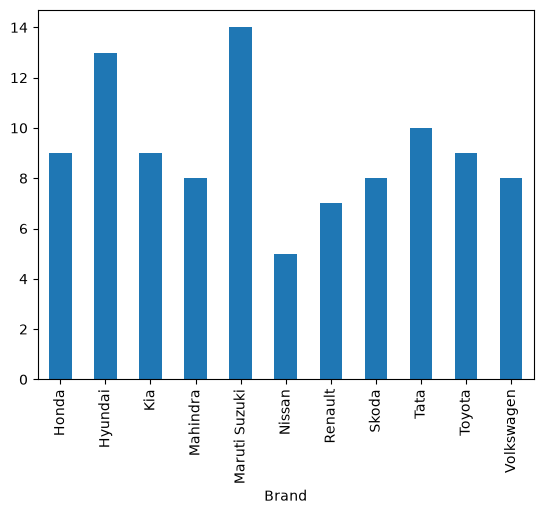

In [30]:
data.groupby("Brand")["Model"].count().plot(kind = "bar")

<Axes: xlabel='Model'>

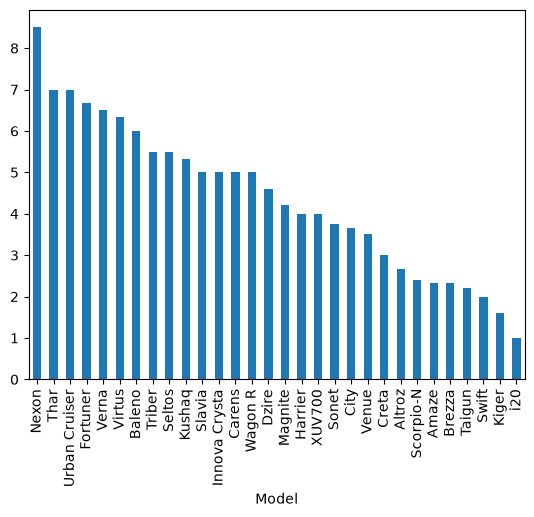

In [41]:
a = data.groupby("Model")["Age_Years"].mean()
a.sort_values(ascending = False).plot(kind = "bar")

In [47]:
b = data[data["Age_Years"]>5].groupby("Model")["Price_Lakh"].mean()
b.sort_values(ascending = False)

Model
Fortuner         9.000000
Innova Crysta    6.000000
Harrier          4.000000
Scorpio-N        4.000000
Seltos           3.000000
Virtus           3.000000
Urban Cruiser    3.000000
Thar             3.000000
Kushaq           2.333333
Taigun           2.000000
Slavia           2.000000
Carens           2.000000
City             2.000000
Nexon            2.000000
Creta            2.000000
Sonet            2.000000
Magnite          1.500000
Amaze            1.000000
Baleno           1.000000
Dzire            1.000000
Triber           1.000000
Venue            1.000000
Verna            1.000000
Name: Price_Lakh, dtype: float64

In [52]:
data.groupby("Transmission")["Brand"].count()

Transmission
Automatic    41
Manual       59
Name: Brand, dtype: int64

<Axes: xlabel='Brand'>

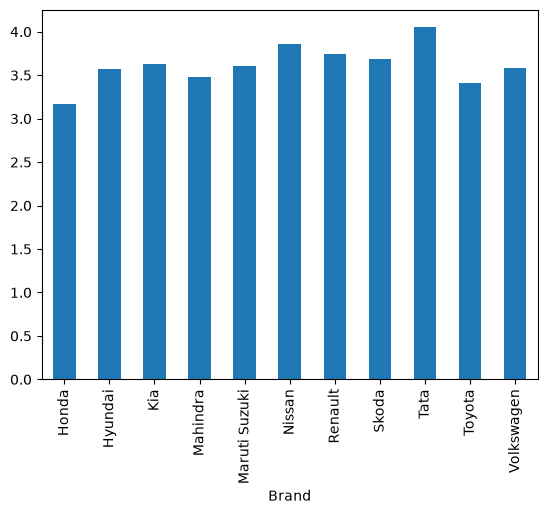

In [57]:
data.groupby("Brand")["Safety_Rating"].mean().plot(kind = "bar")

In [59]:
c = data[data["Brand"] == "Tata"]

In [64]:
c["Price_Lakh"].min()

np.int64(2)

In [65]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'age')

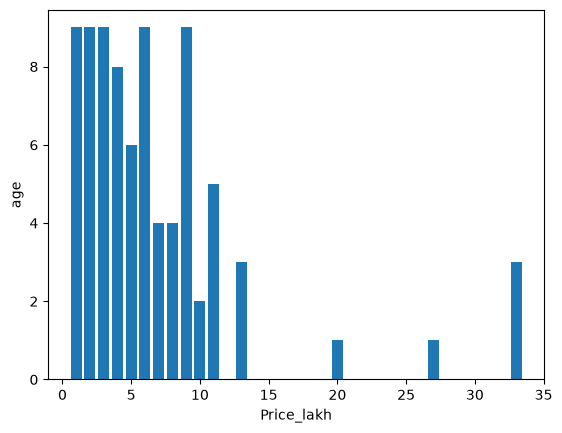

In [77]:
# Plot
plt.Figure(figsize=(10,6))
plt.bar(data['Price_Lakh'], data['Age_Years'])
plt.xlabel("Price_lakh")
plt.ylabel("age")

In [66]:
data.columns

Index(['Brand', 'Model', 'Age_Years', 'Fuel_Type', 'Transmission',
       'Kilometers_Driven', 'Seats', 'Safety_Rating', 'Price_Lakh'],
      dtype='str')

# FC

In [ ]:
from sklearn.preprocessing import MinMaxScaler